# Wellenausbreitung im freien Raum: Fresnel, Rayleigh-Sommerfeld, Fraunhofer

Dieses Notebook zeigt die Propagatoren aus `pyoptics.propagators` an Beispielen,
deren Physik man gut nachvollziehen kann: Beugung an Spalt, Quadrat und Kreisblende,
Talbot-Effekt, evaneszente Wellen und Poisson-Fleck. Nebenbei geht es um die
Numerik, an der FFT-Propagatoren in der Praxis scheitern können: Abtastung,
zyklische Faltung (Wrap-around) und Aliasing der Transferfunktion.

**Konvention:** Felder variieren wie $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.
Eine ebene Welle, die um $z>0$ propagiert, erhält den Faktor $\exp(+i k_z z)$,
evaneszente Wellen klingen wie $\exp(-|k_z| z)$ ab.

Alle Längen sind in µm angegeben.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import fresnel, j1

from pyoptics import propagators as prop
from pyoptics.utils import grid1d, grid2d, freq_grid, wavenumber, k_z
from pyoptics.masks import circular_mask, rectangluar_mask
from pyoptics.analytical import mahajan_on_axis_intensity

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11,
                     "axes.grid": False})

wl = 0.5  # Wellenlänge [µm]

## Ein Hilfsmittel: eindimensionale Probleme

Die Propagatoren arbeiten auf 2D-Gittern. Für Strukturen, die in $y$ invariant
sind (Spalte, Gitter), genügt ein Gitter mit nur zwei Zeilen: Das Feld ist
konstant in $y$, also besitzt sein Spektrum nur die Komponente $k_y = 0$.
So lassen sich viele $z$-Ebenen schnell rechnen und als $xz$-Bild darstellen.

Wichtig für alle Propagatoren: Das Gitter muss $x = 0$ beim Index $N/2$ haben,
wie es `grid1d(-L/2, L/2, N)` liefert (der rechte Endpunkt fehlt, passend zur
Periodizität der FFT).

In [2]:
y_dummy = grid1d(-1, 1, 2)  # [-1, 0]: y = 0 beim Index N//2

def propagate_1d(propagator, u, x, z, wl, **kwargs):
    """Propagiere ein in y invariantes Feld u(x)."""
    field = np.tile(u, (2, 1)).astype(complex)
    out, _, _ = propagator(field, x, y_dummy, z, wl, **kwargs)
    return out[0]

def xz_map(propagator, u, x, z_vals, wl, **kwargs):
    return np.array([propagate_1d(propagator, u, x, z, wl, **kwargs) for z in z_vals])

def plot_xz(ax, U, x, z_vals, title, xlim=None, vmax=None, cmap="inferno", zscale=1.0, zlabel="$z$ [µm]"):
    I = np.abs(U)**2
    im = ax.imshow(I, extent=(x[0], x[-1], z_vals[0]*zscale, z_vals[-1]*zscale), aspect="auto",
                   cmap=cmap, vmax=vmax, interpolation="bilinear")
    ax.set_xlabel("$x$ [µm]"); ax.set_ylabel(zlabel); ax.set_title(title)
    if xlim is not None:
        ax.set_xlim(*xlim)
    return im

## 1. Fresnel-Beugung an einer quadratischen Blende

Eine ebene Welle fällt auf eine quadratische Öffnung der halben Kantenlänge $a$.
Wie das Beugungsbild aussieht, bestimmt allein die **Fresnel-Zahl**

$$N_F = \frac{a^2}{\lambda z},$$

also die Zahl der Fresnel-Zonen, die man vom Aufpunkt aus in der Öffnung sieht.
Für $N_F \gg 1$ sieht man im Wesentlichen den geometrischen Schatten mit
Beugungsrändern, für $N_F \lesssim 1$ geht das Bild in die Fraunhofer-Beugung
(Fernfeld, $\mathrm{sinc}^2$) über.

Für die Fresnel-Näherung gibt es eine analytische Lösung über die
Fresnel-Integrale $C$ und $S$:

$$U(x, y) = \frac{e^{ikz}}{2i}\, F(x)\, F(y), \qquad
  F(x) = \big[C(\beta)+iS(\beta)\big]_{\beta_1}^{\beta_2}, \quad
  \beta_{1,2} = \sqrt{\tfrac{2}{\lambda z}}\,(\mp a - x).$$

Damit lässt sich die Numerik direkt prüfen.

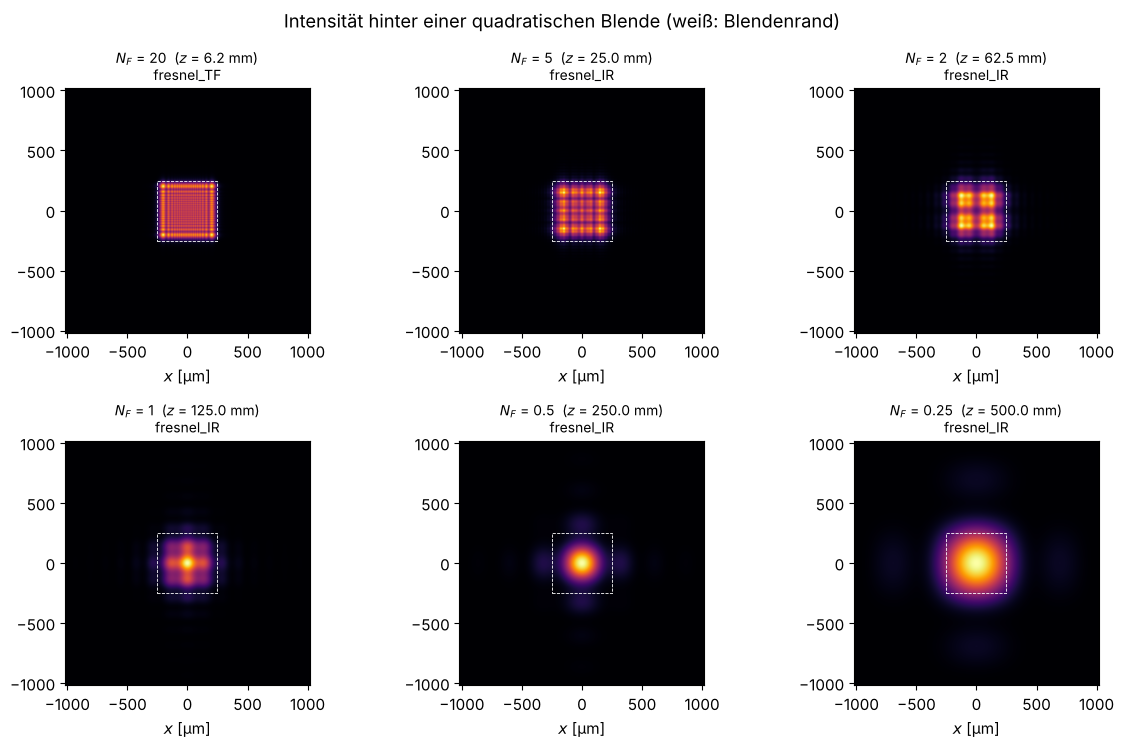

In [3]:
a = 250.0
# Abtastabstand so, dass die Blendenkante genau zwischen zwei Abtastpunkten
# liegt: Dann ist die diskrete Blende exakt 2a breit (bei N_F = 20 ändert schon
# ein Fehler von dx in der Breite die Phase der Randwellen um etwa 1 rad).
N = 1024
dx = 2*a/251
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
aperture = rectangluar_mask(x, y, a, a).astype(complex)

def fresnel_square_1d(x, z, a, wl):
    b1, b2 = np.sqrt(2/(wl*z))*(-a - x), np.sqrt(2/(wl*z))*(a - x)
    S1, C1 = fresnel(b1); S2, C2 = fresnel(b2)
    return (C2 - C1) + 1j*(S2 - S1)

NF_vals = [20, 5, 2, 1, 0.5, 0.25]
results = []
for NF in NF_vals:
    z = a**2/(wl*NF)
    # Transferfunktion (TF) oder Impulsantwort (IR)? Die TF-Chirp ist gut abgetastet
    # für z < dx*L_pad/lambda, die IR für größere z (siehe Abschnitt 5):
    z_crit = dx*(2*L)/wl
    propagator = prop.fresnel_TF if z < z_crit else prop.fresnel_IR
    U, _, _ = prop.propagate_padded(propagator, aperture, x, y, z, wl, pad_factor=2)
    results.append((NF, z, U, propagator.__name__))

fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for ax, (NF, z, U, name) in zip(axes.flat, results):
    ax.imshow(np.abs(U)**2, extent=(x[0], x[-1], y[0], y[-1]), cmap="inferno")
    ax.set_title(f"$N_F$ = {NF}  ($z$ = {z/1000:.1f} mm)\n{name}", fontsize=10)
    ax.set_xlabel("$x$ [µm]")
    ax.plot([-a, a, a, -a, -a], [-a, -a, a, a, -a], "w--", lw=0.6)
fig.suptitle("Intensität hinter einer quadratischen Blende (weiß: Blendenrand)")
fig.tight_layout()

Schnitt bei $y = 0$ im Vergleich mit der analytischen Lösung. Bei großer
Fresnel-Zahl sind die Beugungsfransen am Rand des geometrischen Schattens
deutlich zu sehen; die Mitte der Öffnung ist fast ungestört ($|U|^2 \approx 1$).
Je kleiner $N_F$, desto mehr wird die Intensität in die Mitte gebeugt, bis sich
das Fernfeld ausbildet. Für ungerade Zonenzahlen ist die Mitte hell, für gerade dunkel.

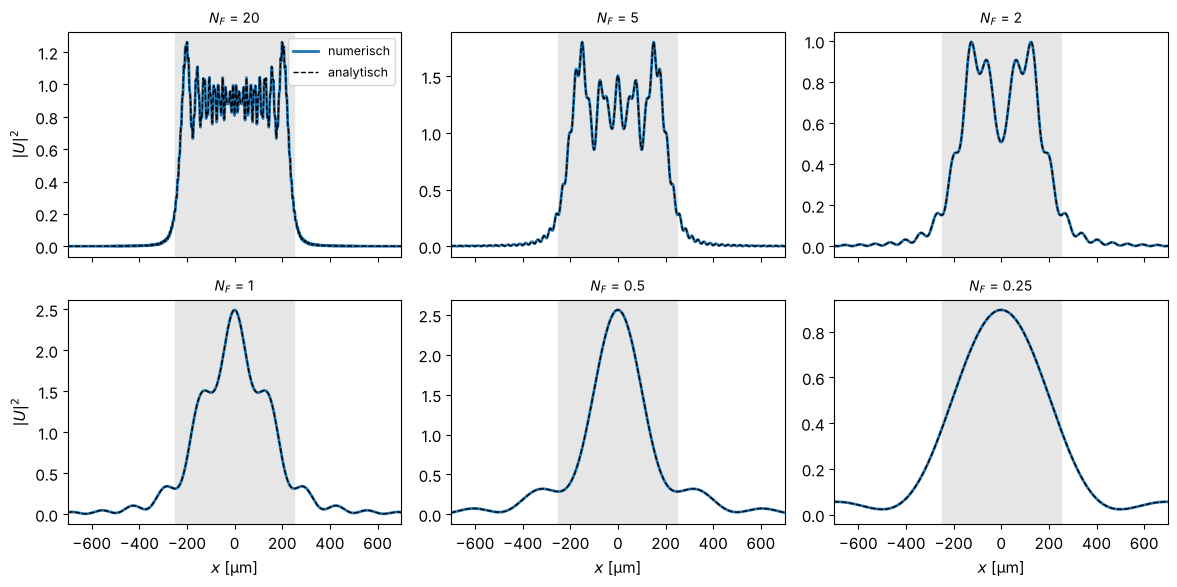

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (NF, z, U, name) in zip(axes.flat, results):
    F = fresnel_square_1d(x, z, a, wl)
    F0 = fresnel_square_1d(np.array([0.0]), z, a, wl)
    I_analytic = 0.25*np.abs(F)**2*np.abs(F0)**2  # Schnitt bei y = 0
    ax.plot(x, np.abs(U[N//2])**2, lw=2, label="numerisch")
    ax.plot(x, I_analytic, "k--", lw=1, label="analytisch")
    ax.axvspan(-a, a, color="0.9", zorder=-1)
    ax.set_title(f"$N_F$ = {NF}", fontsize=10)
    ax.set_xlim(-700, 700)
axes[0, 0].legend(fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("$x$ [µm]")
for ax in axes[:, 0]:
    ax.set_ylabel("$|U|^2$")
fig.tight_layout()

Die Intensität im Zentrum als Funktion der Fresnel-Zahl zeigt das
Wechselspiel der Fresnel-Zonen besonders deutlich. Beim Quadrat sind die
Zonen keine Kreisringe; deshalb fällt das Minimum nicht ganz auf null.

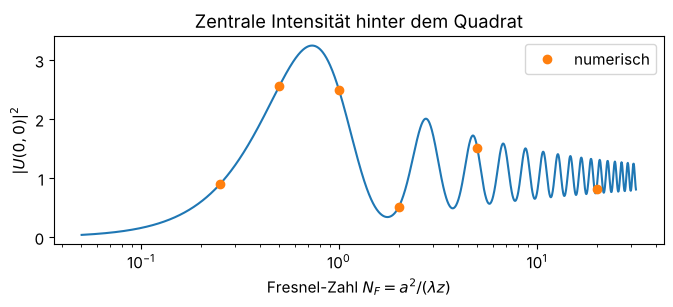

In [5]:
NF_cont = np.logspace(-1.3, 1.5, 1500)
I0 = [0.25*np.abs(fresnel_square_1d(np.array([0.0]), a**2/(wl*nf), a, wl))[0]**4 for nf in NF_cont]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(NF_cont, I0)
ax.plot([r[0] for r in results], [np.abs(r[2][N//2, N//2])**2 for r in results], "o", label="numerisch")
ax.set_xscale("log")
ax.set_xlabel("Fresnel-Zahl $N_F = a^2/(\\lambda z)$"); ax.set_ylabel("$|U(0,0)|^2$")
ax.set_title("Zentrale Intensität hinter dem Quadrat"); ax.legend()
fig.tight_layout()

## 2. Der Talbot-Effekt: Selbstabbildung periodischer Strukturen

Ein Gitter der Periode $d$ beugt in die Ordnungen $k_x = 2\pi m/d$. In
paraxialer Näherung erhält Ordnung $m$ nach der Strecke $z$ die Phase
$-\pi\lambda z m^2/d^2$. Nach der **Talbot-Länge**

$$z_T = \frac{2 d^2}{\lambda}$$

sind alle diese Phasen Vielfache von $2\pi$: Das Gitter bildet sich selbst ab.
Bei $z_T/2$ erscheint es um eine halbe Periode verschoben, bei $z_T/4$ mit
halber Periode. Es entsteht der bekannte **Talbot-Teppich**.

Da das Feld periodisch ist, ist die zyklische FFT-Faltung hier exakt richtig,
es wird kein Padding gebraucht. Der Vergleich der paraxialen Fresnel-Rechnung
mit der exakten Rayleigh-Sommerfeld-Rechnung zeigt, dass die perfekte
Selbstabbildung eine Eigenschaft der paraxialen Näherung ist: Mit
$k_z = \sqrt{k^2 - k_x^2}$ sind die Phasen der hohen Ordnungen nicht mehr exakt
kommensurabel und der Teppich verwischt allmählich.

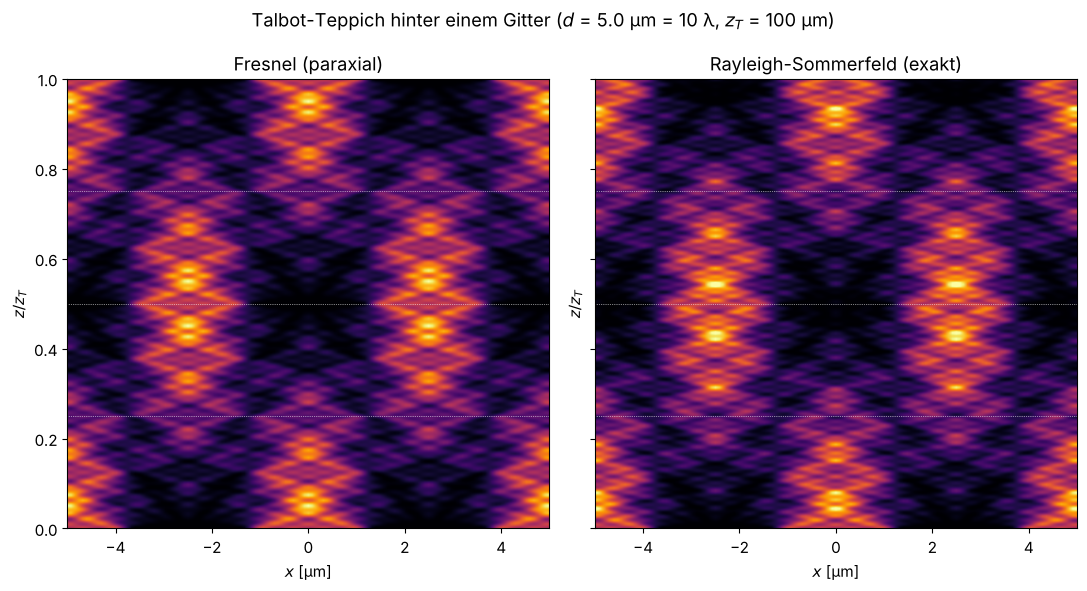

In [6]:
d = 5.0                   # Gitterperiode
z_T = 2*d**2/wl           # Talbot-Länge
Lg, Ng = 8*d, 512
xg = grid1d(-Lg/2, Lg/2, Ng)
# Rechteckgitter (Tastverhältnis 1/2), dessen Fourier-Reihe nach der 7. Ordnung
# abgeschnitten ist: Alle Ordnungen propagieren (sin(theta_7) = 7 lambda/d = 0.7),
# aber die höheren sind schon deutlich nichtparaxial.
m_max = 7
grating = 0.5 + sum(2*np.sin(np.pi*m/2)/(np.pi*m)*np.cos(2*np.pi*m*xg/d) for m in range(1, m_max + 1))

z_vals = np.linspace(0, 1.0*z_T, 600)
carpet_F = xz_map(prop.fresnel_TF, grating, xg, z_vals, wl)
carpet_RS = xz_map(prop.rayleigh_sommerfeld_I_TF, grating, xg, z_vals, wl)

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, U, title in zip(axes, (carpet_F, carpet_RS), ("Fresnel (paraxial)", "Rayleigh-Sommerfeld (exakt)")):
    plot_xz(ax, U, xg, z_vals, title, xlim=(-d, d), vmax=2.0, zscale=1/z_T, zlabel="$z / z_T$")
    for frac in (0.25, 0.5, 0.75):
        ax.axhline(frac, color="w", lw=0.5, ls=":")
fig.suptitle(f"Talbot-Teppich hinter einem Gitter ($d$ = {d} µm = {d/wl:.0f} λ, $z_T$ = {z_T:.0f} µm)")
fig.tight_layout()

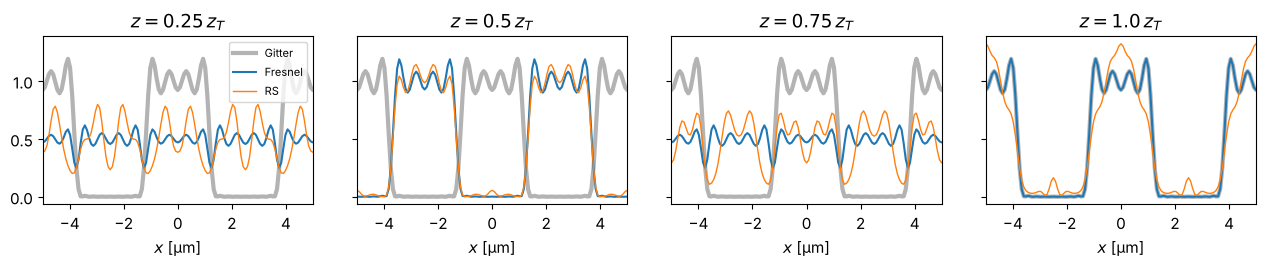

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, frac in zip(axes, (0.25, 0.5, 0.75, 1.0)):
    i = np.argmin(np.abs(z_vals - frac*z_T))
    ax.plot(xg, grating**2, color="0.7", lw=3, label="Gitter")
    ax.plot(xg, np.abs(carpet_F[i])**2, label="Fresnel")
    ax.plot(xg, np.abs(carpet_RS[i])**2, lw=1, label="RS")
    ax.set_xlim(-d, d); ax.set_title(f"$z = {frac}\\,z_T$"); ax.set_xlabel("$x$ [µm]")
axes[0].legend(fontsize=8)
fig.tight_layout()

## 3. Wann versagt die Fresnel-Näherung?

Die Fresnel-Transferfunktion $\exp\left(ikz - i\pi\lambda z (f_x^2+f_y^2)\right)$ ist
die Taylor-Entwicklung von $\exp(i k_z z)$ für kleine Winkel. Sie hat zwei
Schwächen:

1. Für große Ortsfrequenzen ist die Phase falsch, Licht läuft in zu große Winkel.
2. Frequenzen $|f| > 1/\lambda$ sind in Wahrheit **evaneszent**, in der
   Fresnel-Näherung propagieren sie dagegen ungedämpft.

Ein Spalt von nur einer Wellenlänge Breite macht beides sichtbar. Die
Intensität ist logarithmisch dargestellt, damit man das Licht bei großen
Winkeln sieht: Rayleigh-Sommerfeld beschränkt alles auf einen Halbraum
($|\sin\theta| \le 1$), in der Fresnel-Näherung läuft dagegen Licht unter
"unmöglichen" Winkeln weg und das Feld direkt hinter dem Spalt ist verrauscht.

Auffällig sind die Nebenmaxima der Fresnel-Rechnung: Das Fernfeld eines Spalts
der Breite $b$ ist $\mathrm{sinc}^2$ mit der ersten Nullstelle bei
$\sin\theta = \lambda/b$. Für $b = \lambda$ liegt sie genau bei $90°$, die
exakte Rechnung hat also gar keine Nebenmaxima. Die Fresnel-Näherung setzt
dagegen $x/z = \tan\theta$ mit $\sin\theta$ gleich. Damit landet die Richtung
$\sin\theta = 1$ bei $x = z$ statt im Unendlichen, und die Ortsfrequenzen jenseits
davon (in Wahrheit evaneszent) erzeugen Nebenmaxima, die es physikalisch nicht gibt.

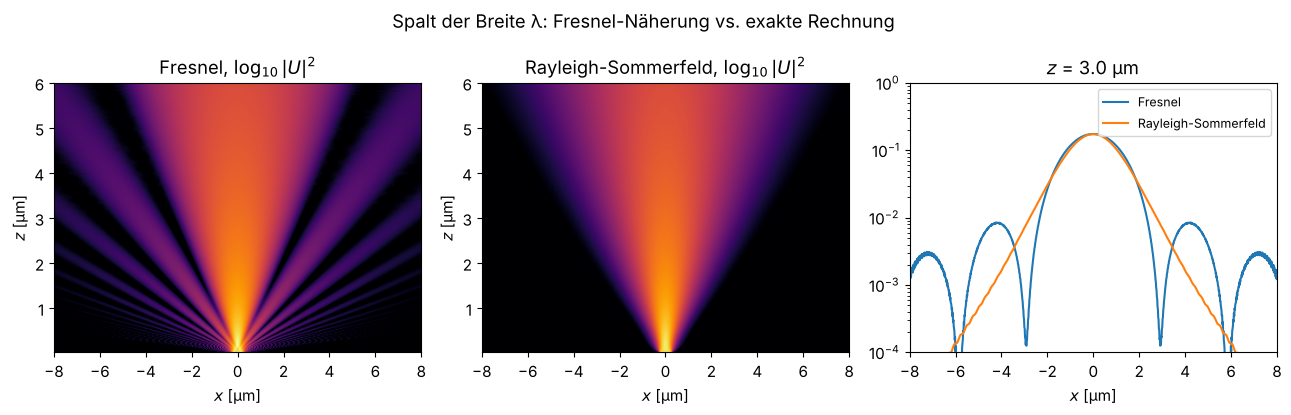

In [8]:
Ls, Ns = 60.0, 4096
xs = grid1d(-Ls/2, Ls/2, Ns)
slit = (np.abs(xs) <= wl/2).astype(float)   # Breite λ
z_vals_s = np.linspace(0.02, 6, 300)

U_F = xz_map(prop.fresnel_TF, slit, xs, z_vals_s, wl)
U_RS = xz_map(prop.rayleigh_sommerfeld_I_TF, slit, xs, z_vals_s, wl)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, U, title in zip(axes, (U_F, U_RS), ("Fresnel", "Rayleigh-Sommerfeld")):
    ax.imshow(np.log10(np.abs(U)**2 + 1e-4), extent=(xs[0], xs[-1], z_vals_s[0], z_vals_s[-1]),
              aspect="auto", cmap="inferno", vmin=-3, vmax=0.3)
    ax.set_xlim(-8, 8); ax.set_xlabel("$x$ [µm]"); ax.set_ylabel("$z$ [µm]")
    ax.set_title(title + ", $\\log_{10}|U|^2$")
iz = np.argmin(np.abs(z_vals_s - 3))
axes[2].semilogy(xs, np.abs(U_F[iz])**2, label="Fresnel")
axes[2].semilogy(xs, np.abs(U_RS[iz])**2, label="Rayleigh-Sommerfeld")
axes[2].set_ylim(1e-4, 1)
axes[2].set_xlim(-8, 8); axes[2].set_xlabel("$x$ [µm]"); axes[2].set_title(f"$z$ = {z_vals_s[iz]:.1f} µm")
axes[2].legend(fontsize=9)
fig.suptitle("Spalt der Breite λ: Fresnel-Näherung vs. exakte Rechnung")
fig.tight_layout()

## 4. Evaneszente Wellen

Die exakte Transferfunktion $H(k_x) = \exp(i k_z z)$ mit $k_z = \sqrt{k^2 - k_x^2}$
ist für $|k_x| < k$ ein reiner Phasenfaktor. Für $|k_x| > k$ ist $k_z$ imaginär
und `utils.k_z()` wählt den Zweig $\mathrm{Im}\,k_z \ge 0$, sodass die Welle
abklingt: $|H| = \exp(-\sqrt{k_x^2 - k^2}\, z)$.

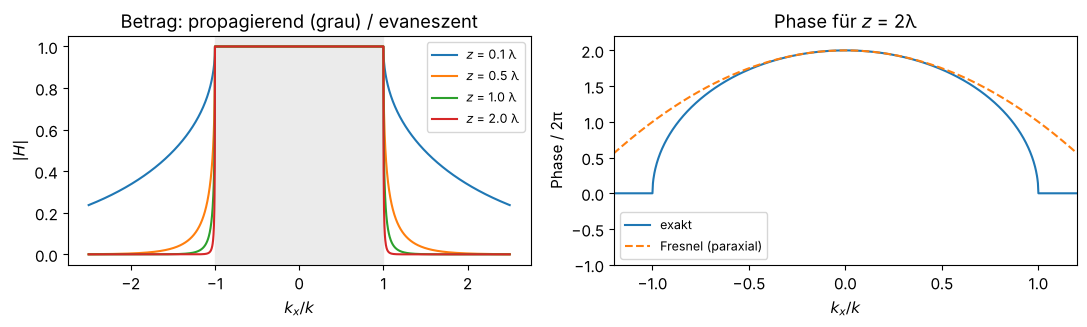

In [9]:
k = wavenumber(wl)
kx = np.linspace(-2.5*k, 2.5*k, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for z in (0.1*wl, 0.5*wl, wl, 2*wl):
    H = np.exp(1j*k_z(k, kx, 0)*z)
    axes[0].plot(kx/k, np.abs(H), label=f"$z$ = {z/wl:.1f} λ")
axes[0].set_xlabel("$k_x / k$"); axes[0].set_ylabel("$|H|$"); axes[0].legend(fontsize=9)
axes[0].axvspan(-1, 1, color="0.92", zorder=-1); axes[0].set_title("Betrag: propagierend (grau) / evaneszent")
H = np.exp(1j*k_z(k, kx, 0)*2*wl)
axes[1].plot(kx/k, np.unwrap(np.angle(H))/(2*np.pi), label="exakt")
axes[1].plot(kx/k, (k*2*wl - kx**2/(2*k)*2*wl)/(2*np.pi), "--", label="Fresnel (paraxial)")
axes[1].set_xlim(-1.2, 1.2); axes[1].set_ylim(-1, 2.2)
axes[1].set_xlabel("$k_x / k$"); axes[1].set_ylabel("Phase / 2π"); axes[1].legend(fontsize=9)
axes[1].set_title("Phase für $z$ = 2λ")
fig.tight_layout()

Ein Gitter mit Periode $d < \lambda$ hat außer der 0. nur evaneszente
Beugungsordnungen. Seine Struktur ist deshalb schon wenige hundert Nanometer
hinter dem Gitter nicht mehr zu sehen: Das ist der Grund für die Auflösungsgrenze
im Fernfeld (und die Idee hinter der Nahfeldmikroskopie). Bei $d > \lambda$
propagieren die $\pm 1$. Ordnungen unter $\sin\theta = \lambda/d$ und erzeugen
ein dauerhaftes Interferenzmuster.

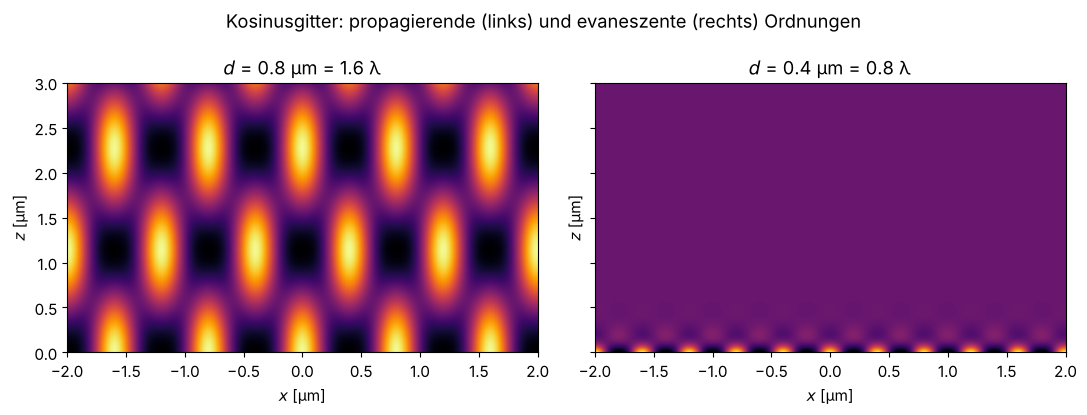

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
z_vals_e = np.linspace(0, 3, 300)
for ax, d_e in zip(axes, (0.8, 0.4)):
    Le, Ne = 20*d_e, 512
    xe = grid1d(-Le/2, Le/2, Ne)
    g = 1 + 0.8*np.cos(2*np.pi*xe/d_e)
    U = xz_map(prop.rayleigh_sommerfeld_I_TF, g, xe, z_vals_e, wl)
    plot_xz(ax, U, xe, z_vals_e, f"$d$ = {d_e} µm = {d_e/wl:.1f} λ", xlim=(-2, 2), vmax=3.3)
fig.suptitle("Kosinusgitter: propagierende (links) und evaneszente (rechts) Ordnungen")
fig.tight_layout()

## 5. Numerische Fallstricke: Wrap-around, Abtastung und Aliasing

### Wrap-around
FFT-Faltungen sind zyklisch. Licht, das das Rechenfenster auf einer Seite
verlässt, tritt auf der anderen wieder ein. Ein schräg laufender Gauß-Strahl
zeigt das. Zero-Padding (für 2D-Felder: `propagate_padded()`) vergrößert das Fenster mit Nullen und schneidet
das Ergebnis wieder auf die Originalgröße zu.

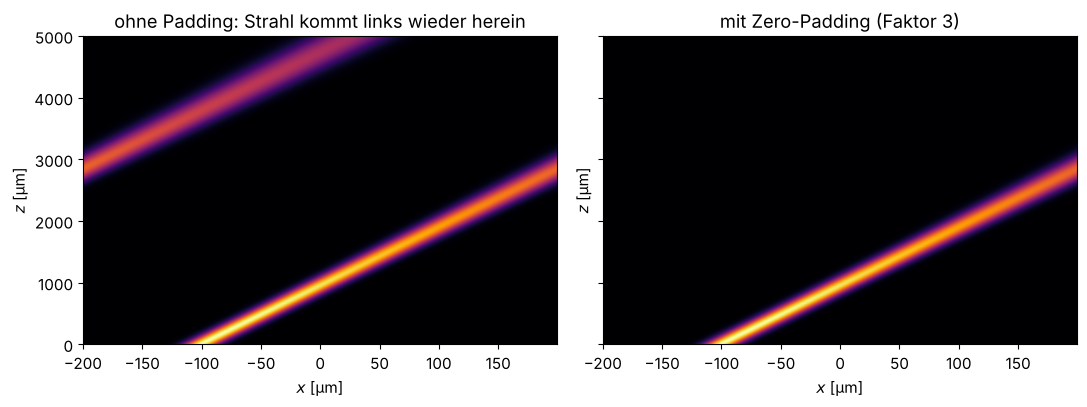

In [11]:
Lw, Nw = 400.0, 1024
xw = grid1d(-Lw/2, Lw/2, Nw)
theta = np.deg2rad(6)
beam = np.exp(-(xw + 100)**2/20**2)*np.exp(1j*k*np.sin(theta)*xw)
z_vals_w = np.linspace(0, 5000, 200)

U_nopad = xz_map(prop.rayleigh_sommerfeld_I_TF, beam, xw, z_vals_w, wl)

# Für das 1D-Hilfsmittel padden wir nur in x (propagate_padded() würde auch die
# zwei y-Zeilen mit Nullen auffüllen und damit die y-Invarianz zerstören):
pad = 3
xw_pad = grid1d(-pad*Lw/2, pad*Lw/2, pad*Nw)
beam_pad = np.zeros(pad*Nw, dtype=complex)
off = pad*Nw//2 - Nw//2
beam_pad[off:off + Nw] = beam
U_pad = xz_map(prop.rayleigh_sommerfeld_I_TF, beam_pad, xw_pad, z_vals_w, wl)[:, off:off + Nw]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
plot_xz(axes[0], U_nopad, xw, z_vals_w, "ohne Padding: Strahl kommt links wieder herein")
plot_xz(axes[1], U_pad, xw, z_vals_w, "mit Zero-Padding (Faktor 3)")
fig.tight_layout()

### Transferfunktion oder Impulsantwort?

Mathematisch sind Faltung mit der Impulsantwort (IR) und Multiplikation mit der
Transferfunktion (TF) identisch, numerisch nicht. Die Fresnel-TF ist ein
Chirp in der Frequenz, die IR ein Chirp im Ort. Bei Fensterbreite $L$ und
Abtastabstand $\Delta x$ ist

* die **TF** gut abgetastet für $z \le \Delta x\, L / \lambda$ (kurze Distanzen),
* die **IR** gut abgetastet für $z \ge \Delta x\, L / \lambda$ (lange Distanzen).

Genau bei $\Delta x = \lambda z / L$ sind beide gut abgetastet ("kritische
Abtastung", siehe `suggest_N_critical()`). Abschnitt 1 hat den Propagator nach
diesem Kriterium gewählt; hier sieht man, was mit der falschen Wahl passiert.

kritische Distanz z_crit = dx L / lambda = 1961 µm
suggest_N_critical(L, z_crit, wl) = 1001


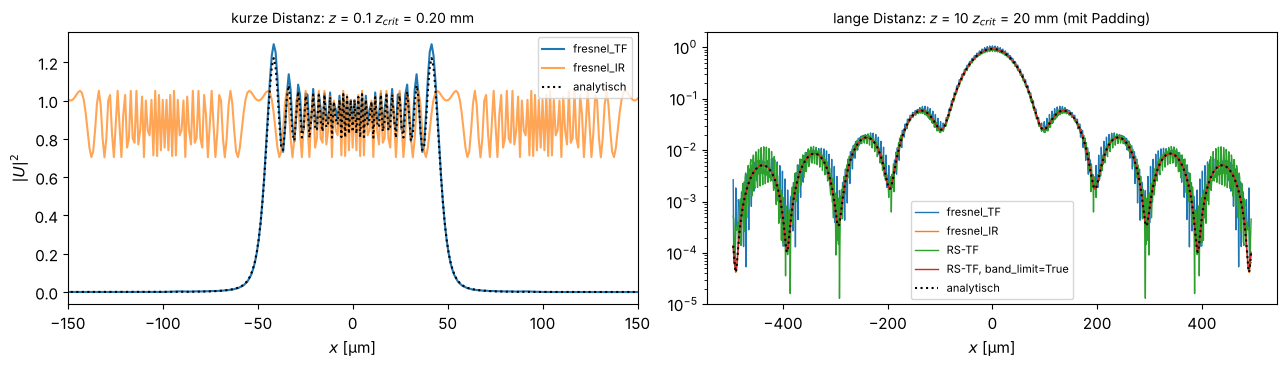

In [12]:
a_sq = 50.0
Nc = 1000
dxc = 2*a_sq/101          # Kante wieder genau zwischen zwei Abtastpunkten
Lc = Nc*dxc
xc, yc, _, _ = grid2d(-Lc/2, Lc/2, -Lc/2, Lc/2, Nc)
square = rectangluar_mask(xc, yc, a_sq, a_sq).astype(complex)
z_crit = dxc*Lc/wl
print(f"kritische Distanz z_crit = dx L / lambda = {z_crit:.0f} µm")
print("suggest_N_critical(L, z_crit, wl) =", prop.suggest_N_critical(Lc, z_crit, wl))

def I_square_ref(z):
    return 0.25*np.abs(fresnel_square_1d(xc, z, a_sq, wl))**2*np.abs(fresnel_square_1d(np.array([0.0]), z, a_sq, wl))**2

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
z = 0.1*z_crit
U_TF, _, _ = prop.fresnel_TF(square, xc, yc, z, wl)
U_IR, _, _ = prop.fresnel_IR(square, xc, yc, z, wl)
axes[0].plot(xc, np.abs(U_TF[Nc//2])**2, label="fresnel_TF")
axes[0].plot(xc, np.abs(U_IR[Nc//2])**2, label="fresnel_IR", alpha=0.7)
axes[0].plot(xc, I_square_ref(z), "k:", label="analytisch")
axes[0].set_xlim(-150, 150); axes[0].set_xlabel("$x$ [µm]"); axes[0].set_ylabel("$|U|^2$")
axes[0].set_title(f"kurze Distanz: $z$ = 0.1 $z_{{crit}}$ = {z/1000:.2f} mm", fontsize=10)
axes[0].legend(fontsize=8, loc="upper right")

z = 10*z_crit
for propagator, kwargs, label in ((prop.fresnel_TF, {}, "fresnel_TF"),
                                   (prop.fresnel_IR, {}, "fresnel_IR"),
                                   (prop.rayleigh_sommerfeld_I_TF, {}, "RS-TF"),
                                   (prop.rayleigh_sommerfeld_I_TF, {"band_limit": True}, "RS-TF, band_limit=True")):
    U, _, _ = prop.propagate_padded(propagator, square, xc, yc, z, wl, pad_factor=2, **kwargs)
    axes[1].semilogy(xc, np.abs(U[Nc//2])**2, label=label, lw=1)
axes[1].semilogy(xc, I_square_ref(z), "k:", label="analytisch")
axes[1].set_ylim(1e-5, 2); axes[1].set_xlabel("$x$ [µm]")
axes[1].set_title(f"lange Distanz: $z$ = 10 $z_{{crit}}$ = {z/1000:.0f} mm (mit Padding)", fontsize=10)
axes[1].legend(fontsize=8, loc="lower center")
fig.tight_layout()

Links ist die Impulsantwort unterabgetastet: `fresnel_IR` liefert außerhalb der
Blende Unsinn, `fresnel_TF` stimmt. Rechts ist es umgekehrt: Die Transferfunktionen
(Fresnel und Rayleigh-Sommerfeld) erzeugen durch Aliasing ein Rauschen in den
Ausläufern, die Impulsantwort ist sauber.

Für die exakte Transferfunktion $\exp(ik_z z)$ gibt es dafür die
**band-limitierte** Methode von Matsushima und Shimobaba (`band_limit=True`):
Sie setzt die Frequenzen auf null, deren Phase nicht mehr korrekt abgetastet
ist, und wird zusammen mit Padding benutzt. Damit verschwindet das Rauschen
(rote Kurve), ohne dass man die Paraxialnäherung braucht.

## 6. Fraunhofer-Beugung: das Airy-Scheibchen

Im Fernfeld ($N_F \ll 1$) ist das Beugungsbild die Fourier-Transformierte der
Blende. `fraunhofer()` liefert das Feld auf dem skalierten Gitter
$x' = \lambda z f_x$. Für die Kreisblende mit Radius $a$ erhält man das
Airy-Muster

$$I(r) = I_0 \left(\frac{2 J_1(v)}{v}\right)^2, \qquad v = \frac{k a r}{z},$$

mit der ersten Nullstelle bei $r = 0.61\,\lambda z / a$.

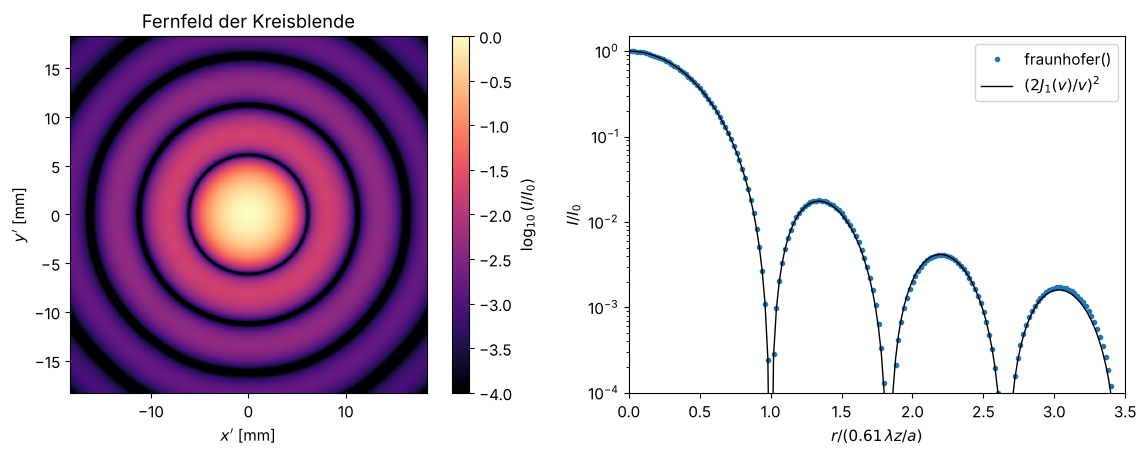

In [13]:
a_c = 50.0
Lf, Nf = 4096.0, 4096
xf, yf, Xf, Yf = grid2d(-Lf/2, Lf/2, -Lf/2, Lf/2, Nf)
disk = circular_mask(xf, yf, a_c).astype(complex)
zf = 1e6  # 1 m
Uf, xn, yn = prop.fraunhofer(disk, xf, yf, zf, wl)
If = np.abs(Uf)**2
If /= If.max()

r = np.abs(xn)
v = k*a_c*r/zf
airy = np.where(v == 0, 1.0, (2*j1(v)/np.where(v == 0, 1, v))**2)
r_zero = 0.61*wl*zf/a_c

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
c = 3*r_zero
sel = np.abs(xn) <= c
im = axes[0].imshow(np.log10(If[np.ix_(np.abs(yn) <= c, sel)] + 1e-6), extent=(-c/1000, c/1000, -c/1000, c/1000),
                    cmap="magma", vmin=-4)
fig.colorbar(im, ax=axes[0], label="$\\log_{10}(I/I_0)$")
axes[0].set_xlabel("$x'$ [mm]"); axes[0].set_ylabel("$y'$ [mm]"); axes[0].set_title("Fernfeld der Kreisblende")
axes[1].semilogy(xn/r_zero, If[Nf//2], "o", ms=3, label="fraunhofer()")
axes[1].semilogy(xn/r_zero, airy, "k-", lw=1, label="$(2J_1(v)/v)^2$")
axes[1].set_xlim(0, 3.5); axes[1].set_ylim(1e-4, 1.5)
axes[1].set_xlabel("$r / (0.61\\,\\lambda z / a)$"); axes[1].set_ylabel("$I/I_0$"); axes[1].legend()
fig.tight_layout()

## 7. Axiale Intensität hinter einer Kreisblende

Auf der Achse einer Kreisblende sind die Fresnel-Zonen exakte Kreisringe gleicher
Fläche. Benachbarte Zonen löschen sich aus: Bei ungerader Zonenzahl ist die
Achse hell (bis zu $4 I_0$, doppelte Amplitude), bei gerader dunkel ($I = 0$).
Für die Rayleigh-Sommerfeld-Theorie gibt es eine geschlossene Lösung (Mahajan),
die in `analytical.mahajan_on_axis_intensity()` implementiert ist. Die grauen
Linien markieren $N_F = a^2/(\lambda z) = 1, 3, 5, 7$.

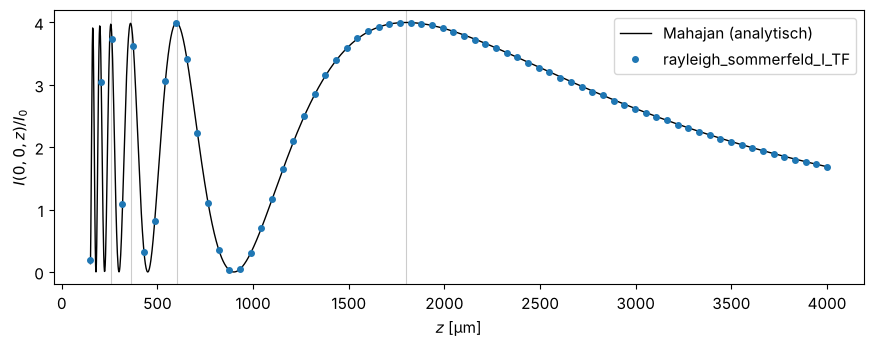

In [14]:
a_m = 30.0
Lm, Nm = 256.0, 512
xm, ym, _, _ = grid2d(-Lm/2, Lm/2, -Lm/2, Lm/2, Nm)
disk_m = circular_mask(xm, ym, a_m).astype(complex)

z_dense = np.linspace(150, 4000, 2000)
I_mahajan = mahajan_on_axis_intensity(a_m, 0.0, 1.0, wl, z_dense)
z_num = np.linspace(150, 4000, 70)
I_num = []
for z in z_num:
    U, _, _ = prop.propagate_padded(prop.rayleigh_sommerfeld_I_TF, disk_m, xm, ym, z, wl,
                                    pad_factor=2, band_limit=True)
    I_num.append(np.abs(U[Nm//2, Nm//2])**2)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(z_dense, I_mahajan, "k-", lw=1, label="Mahajan (analytisch)")
ax.plot(z_num, I_num, "o", ms=4, label="rayleigh_sommerfeld_I_TF")
for m in range(4):  # ungerade Zonenzahl 2m+1 -> Maximum
    ax.axvline(a_m**2/(wl*(2*m + 1)), color="0.8", lw=0.8, zorder=-1)
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("$I(0, 0, z) / I_0$"); ax.legend()
fig.tight_layout()

## 8. Der Poisson-Fleck

Hinter einer undurchsichtigen Kreisscheibe sagt die Wellenoptik auf der Achse
einen hellen Fleck voraus. Poisson hielt das für absurd und damit für ein
Argument gegen Fresnels Theorie, Arago hat den Fleck dann im Experiment gefunden.
Alle Randwellen legen bis zur Achse denselben Weg zurück und interferieren
konstruktiv. Die ebene Welle ist hier periodisch fortgesetzt, die zyklische
Faltung ist also wieder korrekt.

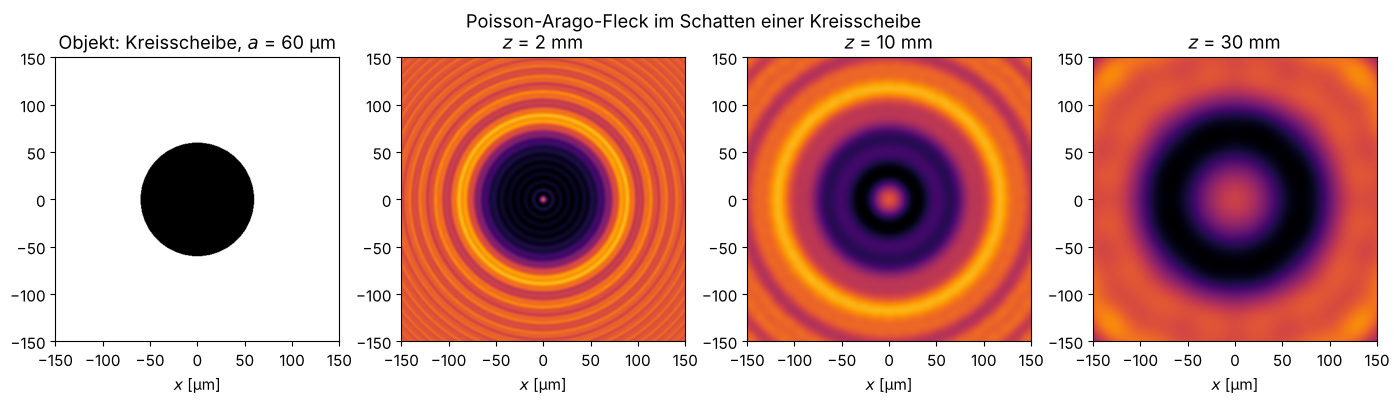

In [15]:
Lp, Np = 600.0, 1024
xp, yp, _, _ = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
obstacle = 1.0 - circular_mask(xp, yp, 60.0)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(obstacle, extent=(xp[0], xp[-1], yp[0], yp[-1]), cmap="gray")
axes[0].set_title("Objekt: Kreisscheibe, $a$ = 60 µm")
for ax, z in zip(axes[1:], (2000, 10000, 30000)):
    U, _, _ = prop.rayleigh_sommerfeld_I_TF(obstacle.astype(complex), xp, yp, z, wl, band_limit=True)
    ax.imshow(np.abs(U)**2, extent=(xp[0], xp[-1], yp[0], yp[-1]), cmap="inferno", vmax=1.6)
    ax.set_title(f"$z$ = {z/1000:.0f} mm")
for ax in axes:
    ax.set_xlim(-150, 150); ax.set_ylim(-150, 150); ax.set_xlabel("$x$ [µm]")
fig.suptitle("Poisson-Arago-Fleck im Schatten einer Kreisscheibe")
fig.tight_layout()